# Linear Regression Lab

**Aim:** Implement Simple and Multiple Linear Regression, predict continuous values, and evaluate the models using **RMSE** and **R²**.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np


In [2]:
# Load the dataset
df = pd.read_csv('data.csv')

print(df.shape)
df.head()


(6012, 144)


,R_fighter,B_fighter,Referee,date,location,Winner,title_bout,weight_class,B_avg_KD,B_avg_opp_KD,...,R_win_by_Decision_Unanimous,R_win_by_KO/TKO,R_win_by_Submission,R_win_by_TKO_Doctor_Stoppage,R_Stance,R_Height_cms,R_Reach_cms,R_Weight_lbs,B_age,R_age
0,Adrian Yanez,Gustavo Lopez,Chris Tognoni,2021-03-20,"Las Vegas, Nevada, USA",Red,False,Bantamweight,0.000,0.0,...,0,1,0,0,Orthodox,170.18,177.80,135.0,31.0,27.0
1,Trevin Giles,Roman Dolidze,Herb Dean,2021-03-20,"Las Vegas, Nevada, USA",Red,False,Middleweight,0.500,0.0,...,0,3,0,0,Orthodox,182.88,187.96,185.0,32.0,28.0
2,Tai Tuivasa,Harry Hunsucker,Herb Dean,2021-03-20,"Las Vegas, Nevada, USA",Red,False,Heavyweight,NaN,NaN,...,1,3,0,0,Southpaw,187.96,190.50,264.0,32.0,28.0
3,Cheyanne Buys,Montserrat Conejo,Mark Smith,2021-03-20,"Las Vegas, Nevada, USA",Blue,False,WomenStrawweight,NaN,NaN,...,0,0,0,0,Switch,160.02,160.02,115.0,28.0,25.0
4,Marion Reneau,Macy Chiasson,Mark Smith,2021-03-20,"Las Vegas, Nevada, USA",Blue,False,WomenBantamweight,0.125,0.0,...,1,2,2,0,Orthodox,167.64,172.72,135.0,29.0,43.0


## 1. Simple Linear Regression

We will predict **R_Weight_lbs** using only **R_Height_cms**.

In [3]:
# Select required columns and remove missing values
data_simple = df[['R_Height_cms', 'R_Weight_lbs']].dropna()

X = data_simple[['R_Height_cms']]
y = data_simple['R_Weight_lbs']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

# Make predictions
y_pred_simple = simple_model.predict(X_test)

print('Coefficient:', simple_model.coef_[0])
print('Intercept:', simple_model.intercept_)


Coefficient: 3.185632568105401
Intercept: -399.3074411469812


In [4]:
# Evaluate Simple Linear Regression
rmse_simple = np.sqrt(mean_squared_error(y_test, y_pred_simple))
r2_simple = r2_score(y_test, y_pred_simple)

print('Simple Linear Regression')
print('RMSE:', rmse_simple)
print('R2 Score:', r2_simple)


Simple Linear Regression
RMSE: 21.270018727431328
R2 Score: 0.6445207967699568


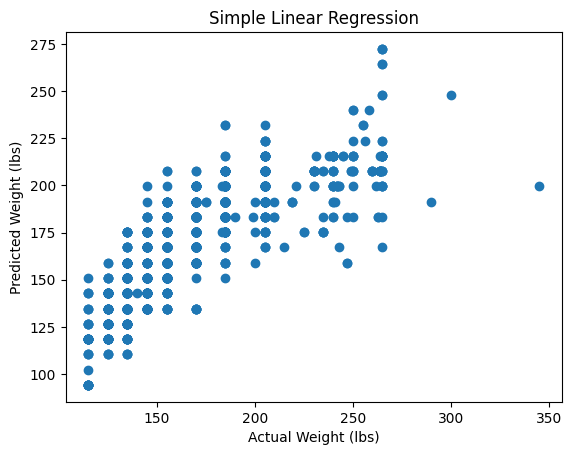

In [5]:
# Plot actual vs predicted values
plt.scatter(y_test, y_pred_simple)
plt.xlabel('Actual Weight (lbs)')
plt.ylabel('Predicted Weight (lbs)')
plt.title('Simple Linear Regression')
plt.show()


## 2. Multiple Linear Regression

Now we use **height, reach, and age** to predict **R_Weight_lbs**.

In [6]:
# Select columns and remove missing values
data_multiple = df[['R_Height_cms', 'R_Reach_cms', 'R_age', 'R_Weight_lbs']].dropna()

X = data_multiple[['R_Height_cms', 'R_Reach_cms', 'R_age']]
y = data_multiple['R_Weight_lbs']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

# Make predictions
y_pred_multiple = multiple_model.predict(X_test)

print('Coefficients:')
for feature, coef in zip(X.columns, multiple_model.coef_):
    print(feature, ':', coef)
print('Intercept:', multiple_model.intercept_)


Coefficients:
R_Height_cms : 2.1589070912807315
R_Reach_cms : 0.8543742195383439
R_age : 1.0561829253119945
Intercept: -405.50701280043097


In [7]:
# Evaluate Multiple Linear Regression
rmse_multiple = np.sqrt(mean_squared_error(y_test, y_pred_multiple))
r2_multiple = r2_score(y_test, y_pred_multiple)

print('Multiple Linear Regression')
print('RMSE:', rmse_multiple)
print('R2 Score:', r2_multiple)


Multiple Linear Regression
RMSE: 20.241286557767058
R2 Score: 0.675686524203153


In [8]:
# Compare both models
results = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'RMSE': [rmse_simple, rmse_multiple],
    'R2 Score': [r2_simple, r2_multiple]
})

results


,Model,RMSE,R2 Score
0,Simple Linear Regression,21.270019,0.644521
1,Multiple Linear Regression,20.241287,0.675687


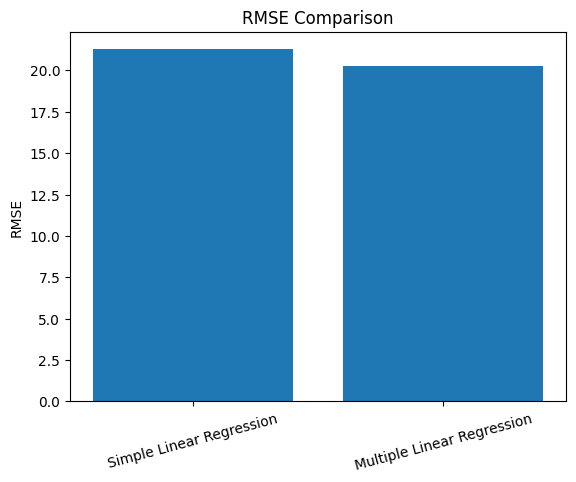

In [9]:
# Compare RMSE
plt.bar(results['Model'], results['RMSE'])
plt.ylabel('RMSE')
plt.title('RMSE Comparison')
plt.xticks(rotation=15)
plt.show()


## Conclusion

- **RMSE:** Lower value means better prediction error.
- **R²:** Higher value means the model explains more variation in the target.
- Compare the two models using these two metrics.
- The multiple linear regression model uses more input features than the simple model.